# 00 — Data Acquisition

## Project
Predictive Maintenance for Dairy Manufacturing: A Data-Driven Approach to Reducing Equipment Downtime

## Objective
This notebook downloads and loads the UCI AI4I 2020 Predictive Maintenance Dataset.

The dataset contains synthetic industrial-machine observations. It is used in this independent portfolio project to investigate predictive-maintenance methods inspired by dairy manufacturing.

## Data source
UCI Machine Learning Repository:
https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

## Workflow
1. Define project paths.
2. Download the dataset from UCI.
3. Extract and load the CSV file.
4. Confirm that the dataset was loaded correctly.

In [1]:
import pandas as pd
import requests
import certifi
import zipfile
from io import BytesIO

In [2]:
from pathlib import Path

# The notebook is inside the notebooks/ folder
project_dir = Path.cwd().parent

# Project data folders
data_dir = project_dir / "data" / "raw"
processed_data_dir = project_dir / "data" / "processed"

# Create folders if they do not already exist
data_dir.mkdir(parents=True, exist_ok=True)
processed_data_dir.mkdir(parents=True, exist_ok=True)

print("Project directory:", project_dir)
print("Raw data directory:", data_dir)
print("Processed data directory:", processed_data_dir)

Project directory: C:\Users\hp\Documents\GitHub\predictive-maintenance-dairy
Raw data directory: C:\Users\hp\Documents\GitHub\predictive-maintenance-dairy\data\raw
Processed data directory: C:\Users\hp\Documents\GitHub\predictive-maintenance-dairy\data\processed


In [3]:
import pandas as pd

csv_path = data_dir / "ai4i2020.csv"

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
# Check column names, data types, and non-missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

### Download and extract the dataset

In [5]:
# Official UCI dataset ZIP
url = (
    "https://archive.ics.uci.edu/static/public/"
    "601/ai4i+2020+predictive+maintenance+dataset.zip"
)

zip_path = data_dir / "ai4i2020.zip"

# Download dataset
response = requests.get(
    url,
    verify=certifi.where(),
    timeout=60
)

response.raise_for_status()

# Save ZIP file
zip_path.write_bytes(response.content)

print("Dataset downloaded successfully.")
print("Saved to:", zip_path)
print("File size:", round(len(response.content) / 1024, 2), "KB")

# Extract ZIP contents
with zipfile.ZipFile(BytesIO(response.content)) as zip_ref:
    zip_ref.extractall(data_dir)

print("\nDataset extracted successfully.")
print("Files in raw data directory:")

for file in data_dir.iterdir():
    print("-", file.name)

Dataset downloaded successfully.
Saved to: C:\Users\hp\Documents\GitHub\predictive-maintenance-dairy\data\raw\ai4i2020.zip
File size: 509.93 KB

Dataset extracted successfully.
Files in raw data directory:
- ai4i2020.csv
- ai4i2020.zip


## Load the Dataset

The dataset has been downloaded from the UCI Machine Learning Repository and extracted into the project's raw data directory.

In this section, we load the CSV file into a pandas DataFrame and perform basic checks to confirm that it is available for analysis.

In [6]:
# Path to the extracted CSV file
csv_path = data_dir / "ai4i2020.csv"

# Load the dataset
df = pd.read_csv(csv_path)

# Confirm successful loading
print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

Dataset loaded successfully.
Dataset shape: (10000, 14)

First five rows:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Dataset Overview

The AI4I 2020 Predictive Maintenance Dataset contains 10,000 observations and 14 variables.

Each row represents an observation of an industrial machine. The variables include product type, operating conditions, machine failure status, and failure-mode indicators.

The dataset will be used to explore operating patterns associated with machine failure and later develop predictive models.

In [7]:
# Display dataset dimensions
print(f"Number of observations: {df.shape[0]:,}")
print(f"Number of variables: {df.shape[1]}")

# Display column names and data types
print("\nColumn names and data types:")
df.info()

Number of observations: 10,000
Number of variables: 14

Column names and data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64

## Data Dictionary

The dataset contains identifiers, operating-condition measurements, the target variable, and failure-mode indicators.

| Variable | Description |
|---|---|
| UDI | Unique identifier for each observation |
| Product ID | Identifier for the product |
| Type | Product quality/type category (L, M, or H) |
| Air temperature [K] | Air temperature in Kelvin |
| Process temperature [K] | Process temperature in Kelvin |
| Rotational speed [rpm] | Rotational speed in revolutions per minute |
| Torque [Nm] | Torque in Newton metres |
| Tool wear [min] | Accumulated tool wear in minutes |
| Machine failure | Target variable: 1 indicates failure, 0 indicates no failure |
| TWF | Tool wear failure indicator |
| HDF | Heat dissipation failure indicator |
| PWF | Power failure indicator |
| OSF | Overstrain failure indicator |
| RNF | Random failure indicator |

## Initial Data Quality Checks

This section checks whether the dataset contains duplicate rows, whether the machine and product identifiers are unique, and how many observations belong to each machine type.

In [8]:
# Check for completely duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Check whether identifiers are unique
print("Unique UDI values:", df["UDI"].nunique())
print("Unique Product ID values:", df["Product ID"].nunique())

# Count observations by product type
print("\nObservations by machine type:")
print(df["Type"].value_counts())

# Check the target variable
print("\nMachine failure counts:")
print(df["Machine failure"].value_counts())

print("\nMachine failure percentages:")
print((df["Machine failure"].value_counts(normalize=True) * 100).round(2))

Duplicate rows: 0
Unique UDI values: 10000
Unique Product ID values: 10000

Observations by machine type:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Machine failure counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Machine failure percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


## Initial Data Quality Findings

The dataset contains 10,000 observations and 14 variables. The initial checks found no duplicate rows or missing values. Both UDI and Product ID contain 10,000 unique values.

Machine types are distributed as follows: L represents 60.00% of observations, M represents 29.97%, and H represents 10.03%.

The target variable, Machine failure, is imbalanced: 9,661 observations (96.61%) are non-failures, while 339 observations (3.39%) are failures. This imbalance means that accuracy alone will not be sufficient for evaluating predictive models. Metrics such as recall, precision, F1-score, and the confusion matrix will also be considered.

## Understanding the Variables

Before analysing the data or training models, we need to understand what each variable represents.

The dataset contains identifiers, machine operating conditions, the target variable, and indicators describing specific failure modes.

In [9]:
# Display each column name
for column in df.columns:
    print(column)

UDI
Product ID
Type
Air temperature [K]
Process temperature [K]
Rotational speed [rpm]
Torque [Nm]
Tool wear [min]
Machine failure
TWF
HDF
PWF
OSF
RNF


### Data Dictionary

| Variable | Meaning | Role in this project |
|---|---|---|
| UDI | Unique identifier for each observation | Identifier; exclude from model |
| Product ID | Identifier for the product/machine | Identifier; exclude from model |
| Type | Machine/product category: L, M, or H | Predictor |
| Air temperature [K] | Air temperature in Kelvin | Predictor |
| Process temperature [K] | Process temperature in Kelvin | Predictor |
| Rotational speed [rpm] | Rotational speed in revolutions per minute | Predictor |
| Torque [Nm] | Torque in newton-metres | Predictor |
| Tool wear [min] | Tool wear measured in minutes | Predictor |
| Machine failure | Whether a machine failure occurred: 0 or 1 | Target |
| TWF | Tool wear failure indicator | Exclude from initial predictors |
| HDF | Heat dissipation failure indicator | Exclude from initial predictors |
| PWF | Power failure indicator | Exclude from initial predictors |
| OSF | Overstrain failure indicator | Exclude from initial predictors |
| RNF | Random failure indicator | Exclude from initial predictors |

In [10]:
failure_mode_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

print("Failure-mode indicator counts:")
display(df[failure_mode_columns].sum())

print("\nNumber of observations with at least one failure-mode indicator:")
print((df[failure_mode_columns].sum(axis=1) > 0).sum())

Failure-mode indicator counts:


TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


Number of observations with at least one failure-mode indicator:
348


In [11]:
# Create a flag: does this row have at least one failure-mode indicator?
df["Any failure mode"] = (
    df[failure_mode_columns].sum(axis=1) > 0
).astype(int)

# Compare the overall target with the failure-mode indicators
comparison = pd.crosstab(
    df["Machine failure"],
    df["Any failure mode"],
    rownames=["Machine failure"],
    colnames=["Any failure-mode indicator"]
)

display(comparison)

# Count rows where the two disagree
mismatch_count = (
    df["Machine failure"] != df["Any failure mode"]
).sum()

print("Number of mismatched observations:", mismatch_count)

Any failure-mode indicator,0,1
Machine failure,,
0,9643,18
1,9,330


Number of mismatched observations: 27


### Consistency Check: Failure Labels

The overall `Machine failure` target was compared with a derived indicator showing whether any of the five failure-mode columns was active.

The two definitions disagreed for 27 observations:
- 18 observations had `Machine failure = 0` but at least one active failure-mode indicator.
- 9 observations had `Machine failure = 1` but no active failure-mode indicator.

All 10,000 observations are retained at this stage. The designated `Machine failure` column remains the prediction target, while the individual failure-mode indicators are excluded from the initial predictor set to reduce the risk of target leakage.

In [12]:
# Columns that identify records, rather than describe operating conditions
identifier_columns = ["UDI", "Product ID"]

# Columns that describe specific failure modes
failure_mode_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# The outcome we want to predict
target_column = "Machine failure"

# Initial predictors: operating conditions and machine type
feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Separate predictors (X) and target (y)
X = df[feature_columns].copy()
y = df[target_column].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nPredictor columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (10000, 6)
Target shape: (10000,)

Predictor columns:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


## Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the data before building predictive models.

We begin by examining summary statistics for the numerical operating variables. This includes their typical values, spread, and minimum and maximum values.

In [13]:
# Select the numerical operating variables
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Generate summary statistics
df[numerical_features].describe().round(2)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.0,10000.00,10000.00,10000.00,10000.00
mean,300.0,310.01,1538.78,39.99,107.95
std,2.0,1.48,179.28,9.97,63.65
min,295.3,305.70,1168.00,3.80,0.00
25%,298.3,308.80,1423.00,33.20,53.00
50%,300.1,310.10,1503.00,40.10,108.00
75%,301.5,311.10,1612.00,46.80,162.00
max,304.5,313.80,2886.00,76.60,253.00


## Operating Conditions by Machine Failure Status

We compare numerical operating conditions between observations with and without machine failure.

This comparison helps identify variables whose distributions differ between the two groups. These are exploratory associations, not evidence that a variable causes machine failure.

In [14]:
# Calculate summary statistics separately for each target group
failure_summary = df.groupby("Machine failure")[numerical_features].mean().T

failure_summary.columns = ["No failure", "Failure"]

# Add the difference between the two group means
failure_summary["Difference (Failure - No failure)"] = (
    failure_summary["Failure"] - failure_summary["No failure"]
)

failure_summary.round(2)

,No failure,Failure,Difference (Failure - No failure)
Air temperature [K],299.97,300.89,0.91
Process temperature [K],310.00,310.29,0.29
Rotational speed [rpm],1540.26,1496.49,-43.77
Torque [Nm],39.63,50.17,10.54
Tool wear [min],106.69,143.78,37.09


## Comparing Operating-Condition Distributions

Boxplots compare the distributions of each numerical operating variable for failure and non-failure observations.

They help us examine differences in medians, spread, and potential outliers. Because failures are relatively rare, the plots should be interpreted with care.

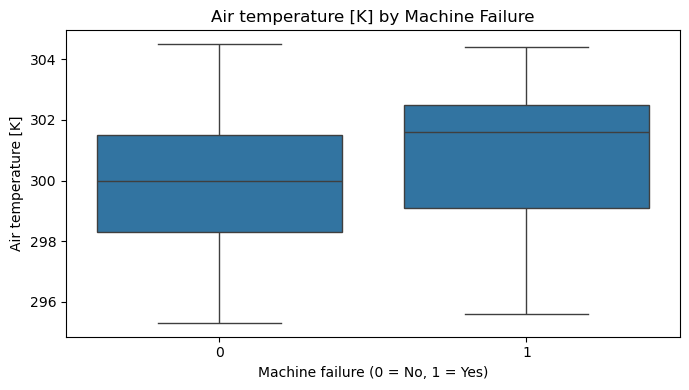

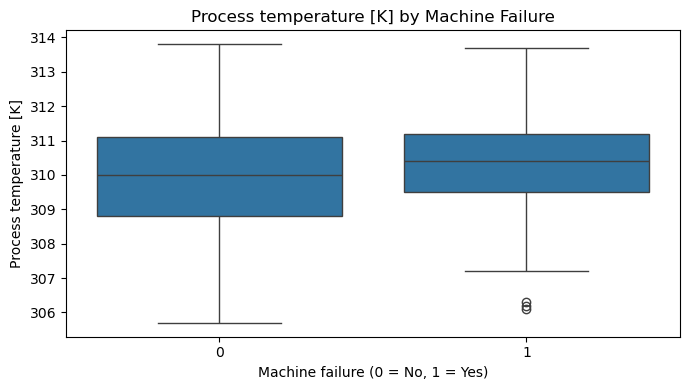

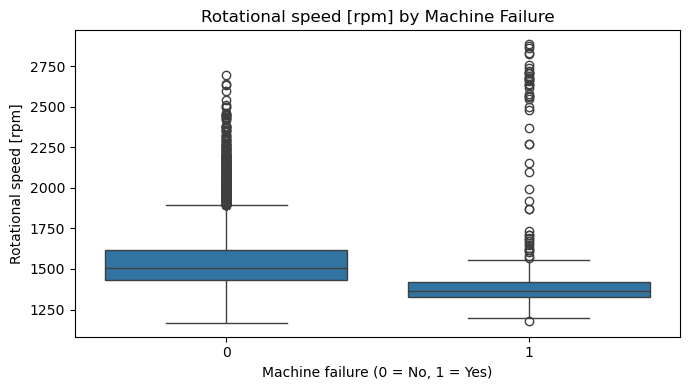

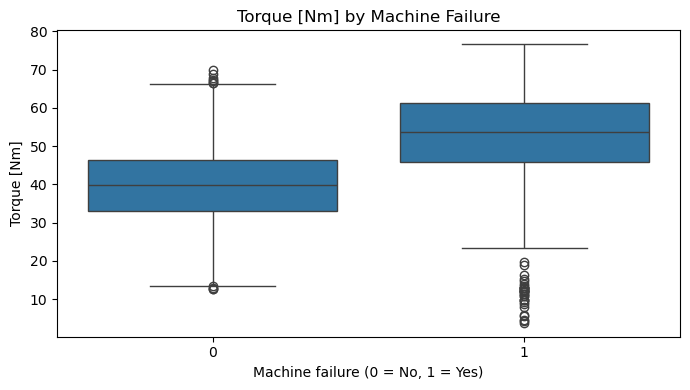

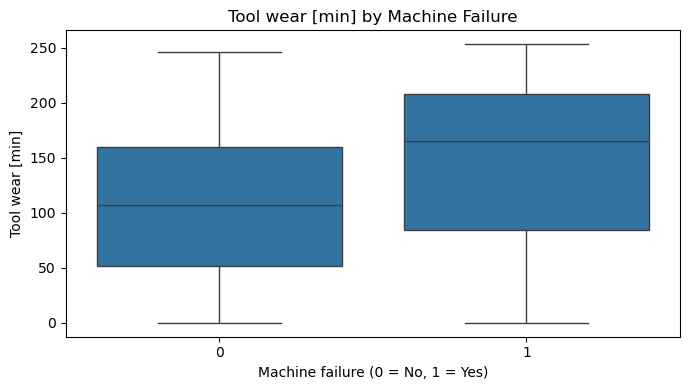

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

for feature in numerical_features:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature
    )

    plt.title(f"{feature} by Machine Failure")
    plt.xlabel("Machine failure (0 = No, 1 = Yes)")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

### Interpretation: Operating Conditions by Failure Status

The boxplots show differences in the distributions of operating conditions between observations with and without machine failure.

Torque and tool wear are shifted toward higher values in the failure group, while rotational speed is shifted toward lower values. Air temperature is slightly higher in the failure group, whereas process temperature shows substantial overlap between the two groups.

The distributions overlap for all five variables, indicating that no single operating condition perfectly separates failures from non-failures. These observations are exploratory and do not establish causal relationships.

The findings motivate evaluating multiple operating variables together in predictive models.

In [16]:
# Count failures and observations for each machine type
type_failure_table = pd.crosstab(
    df["Type"],
    df["Machine failure"],
    margins=True
)

display(type_failure_table)

# Calculate failure rate within each type
failure_rate_by_type = (
    df.groupby("Type")["Machine failure"]
    .mean()
    .mul(100)
    .round(2)
)

print("\nFailure rate by machine type (%):")
display(failure_rate_by_type)

Machine failure,0,1,All
Type,,,
H,982,21,1003
L,5765,235,6000
M,2914,83,2997
All,9661,339,10000



Failure rate by machine type (%):


Type
H    2.09
L    3.92
M    2.77
Name: Machine failure, dtype: float64

### Interpretation: Failure Rate by Machine Type

Failure rates differ across the three machine types. Type L has the highest observed failure rate (3.92%), followed by type M (2.77%) and type H (2.09%).

Although type L accounts for the largest number of failures, it also represents 60% of all observations. Therefore, failure rates are more informative than raw failure counts when comparing machine types.

These differences suggest that machine type may contain useful predictive information, but its individual predictive strength must be evaluated alongside the numerical operating conditions.

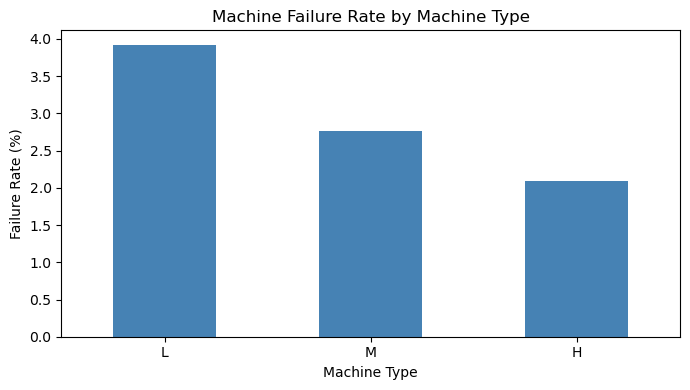

In [17]:
plt.figure(figsize=(7, 4))

failure_rate_by_type.sort_values(ascending=False).plot(
    kind="bar",
    color="steelblue"
)

plt.title("Machine Failure Rate by Machine Type")
plt.xlabel("Machine Type")
plt.ylabel("Failure Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The bar chart confirms that type L has the highest observed machine failure rate, followed by type M and type H. Machine type may provide useful predictive information, although its contribution should be evaluated alongside the numerical operating conditions.

## Correlation Analysis

Correlation analysis examines linear relationships between numerical operating variables.

It helps identify predictors that may contain overlapping information. Correlation does not imply causation, and low correlation does not necessarily mean that a variable is unimportant for predicting machine failure.

In [18]:
# Calculate correlations among numerical operating variables
correlation_matrix = df[numerical_features].corr()

# Display the correlation matrix
correlation_matrix.round(2)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Air temperature [K],1.00,0.88,0.02,-0.01,0.01
Process temperature [K],0.88,1.00,0.02,-0.01,0.01
Rotational speed [rpm],0.02,0.02,1.00,-0.88,0.00
Torque [Nm],-0.01,-0.01,-0.88,1.00,-0.00
Tool wear [min],0.01,0.01,0.00,-0.00,1.00


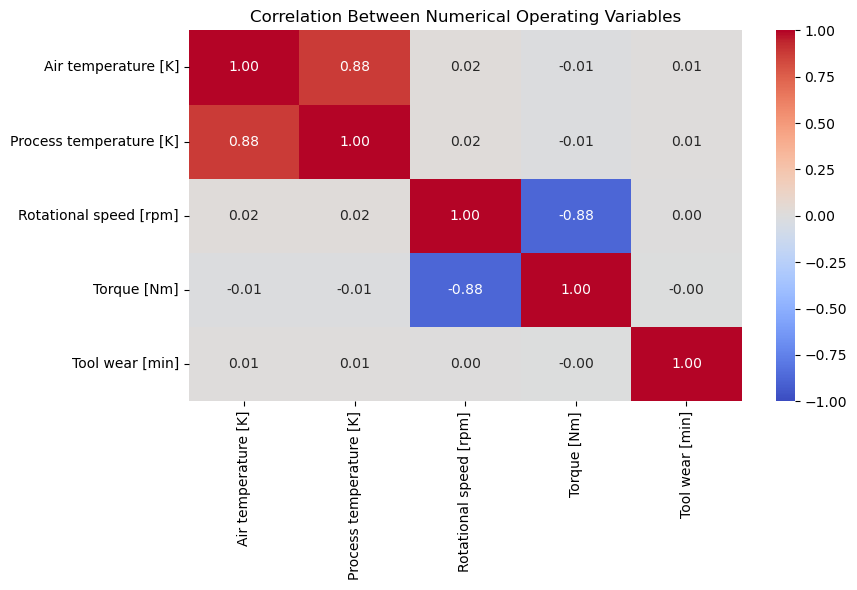

In [19]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Operating Variables")
plt.tight_layout()
plt.show()

### Interpretation: Correlation Analysis

The correlation matrix shows a strong positive linear relationship between air temperature and process temperature (r = 0.88), and a strong negative linear relationship between rotational speed and torque (r = -0.88).

The remaining numerical variable pairs have correlations close to zero.

These relationships suggest that some predictors may contain overlapping information. However, all numerical predictors are retained for the initial modelling stage. Their usefulness and potential multicollinearity effects will be assessed during model evaluation.

Correlation describes linear association and does not establish causation.

## EDA Summary and Key Findings

The initial exploratory analysis of the UCI AI4I 2020 Predictive Maintenance Dataset identified the following:

- The dataset contains 10,000 observations and 14 variables, with no missing values or duplicate rows.
- Machine failure is imbalanced: 339 observations (3.39%) are failures and 9,661 (96.61%) are non-failures.
- The overall failure label disagrees with the five failure-mode indicators for 27 observations. All observations are retained, and `Machine failure` remains the target.
- Failure observations have higher average torque and tool wear, and lower average rotational speed, than non-failure observations.
- Type L has the highest observed failure rate (3.92%), followed by type M (2.77%) and type H (2.09%).
- Air temperature and process temperature are strongly positively correlated (r = 0.88).
- Rotational speed and torque are strongly negatively correlated (r = -0.88).
- The distributions of operating conditions overlap between failure and non-failure observations, so no single variable perfectly separates the two groups.

These findings motivate developing and evaluating multivariable predictive models. Because failures are rare, model evaluation will consider recall, precision, F1-score, PR-AUC, and confusion matrices rather than accuracy alone.

The findings are exploratory and do not establish causal relationships.

## Train-Test Split

The dataset is divided into training and test sets.

The training set will be used to fit predictive models, while the test set will be reserved for final evaluation on unseen observations.

A stratified split is used to preserve the proportion of machine failures in both sets. The split is performed before model preprocessing to avoid information leakage.

In [20]:
from sklearn.model_selection import train_test_split

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTest target distribution:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(2))

Training set shape: (8000, 6)
Test set shape: (2000, 6)

Training target distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

Test target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64
Machine failure
0    96.6
1     3.4
Name: proportion, dtype: float64


## Feature Preprocessing

The predictor set contains numerical operating conditions and one categorical variable, `Type`.

We use:
- One-hot encoding to convert `Type` into numerical columns.
- Standardization to scale numerical variables for Logistic Regression.

Preprocessing is fitted on the training data only and then applied to the test data. This prevents information from the test set from influencing model preparation.

## Feature Preprocessing

The dataset contains numerical operating conditions and one categorical variable, `Type`.

We will use:
- One-hot encoding for the categorical variable.
- Standardization for numerical variables.

A scikit-learn `ColumnTransformer` will apply the appropriate transformation to each column, while a `Pipeline` will connect preprocessing with the model.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

In [22]:
# Numerical features
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Categorical feature
categorical_features = ["Type"]

In [23]:
# Transform numerical and categorical columns separately
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [24]:
# Learn preprocessing settings from training data and transform it
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned settings to test data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (8000, 8)
Processed test shape: (2000, 8)


## Baseline Model: Logistic Regression

Logistic Regression is used as the first baseline model.

It estimates the probability of machine failure from the operating conditions. We begin with the default classification threshold of 0.5 and will later examine whether a different threshold improves failure detection.

Because the target is imbalanced, accuracy alone will not be used to judge model performance.

In [25]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using the processed training data
logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [26]:
# Predict the failure class for the unseen test data
y_pred = logistic_model.predict(X_test_processed)

# Estimate the probability of failure for each observation
y_proba = logistic_model.predict_proba(X_test_processed)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [27]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print("PR-AUC (Average Precision):", average_precision_score(y_test, y_proba))

Confusion Matrix:
[[1928    4]
 [  61    7]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.64      0.10      0.18        68

    accuracy                           0.97      2000
   macro avg       0.80      0.55      0.58      2000
weighted avg       0.96      0.97      0.96      2000

ROC-AUC: 0.8993880160759956
PR-AUC (Average Precision): 0.4205369579251732


In [28]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.50, 0.40, 0.30, 0.20, 0.10, 0.05]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Predicted failures": y_pred_threshold.sum()
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(3)

,Threshold,Precision,Recall,F1-score,Predicted failures
0,0.50,0.636,0.103,0.177,11
1,0.40,0.583,0.206,0.304,24
2,0.30,0.523,0.338,0.411,44
3,0.20,0.451,0.471,0.460,71
4,0.10,0.297,0.632,0.404,145
5,0.05,0.179,0.765,0.291,290


## Logistic Regression: Threshold Analysis

The default classification threshold of 0.50 produced high overall accuracy
but low failure recall, detecting only 10.3% of actual failures.

Lowering the threshold increased failure recall, while reducing precision
and increasing the number of machines flagged for inspection.

Among the thresholds explored, 0.20 achieved the highest F1-score (0.460),
with recall of 47.1% and precision of 45.1%. A threshold of 0.10 increased
recall to 63.2%, but reduced precision to 29.7%.

These results illustrate the trade-off between missed failures and false
maintenance alerts. The threshold comparison is exploratory; the final
threshold should be selected using validation data and evaluated on the
untouched test set.

## Model Comparison: Decision Tree and Random Forest

We compare Logistic Regression with tree-based models using the same
stratified train-test split.

A scikit-learn Pipeline combines preprocessing and model training.
This makes the workflow more reproducible and helps prevent data leakage.

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

categorical_features = ["Type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline components defined.")

Preprocessing pipeline components defined.


## Decision Tree Classifier

A Decision Tree learns a sequence of feature-based rules to classify
whether a machine is likely to fail.

We begin with a simple tree and will later examine whether controlling
its complexity improves performance.

In [30]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

decision_tree_pipeline.fit(X_train, y_train)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [31]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Predict classes and failure probabilities
y_pred_tree = decision_tree_pipeline.predict(X_test)
y_proba_tree = decision_tree_pipeline.predict_proba(X_test)[:, 1]

print("Decision Tree — Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

print("\nDecision Tree — Classification Report:")
print(classification_report(y_test, y_pred_tree, zero_division=0))

print("ROC-AUC:", roc_auc_score(y_test, y_proba_tree))
print("PR-AUC (Average Precision):", average_precision_score(y_test, y_proba_tree))

Decision Tree — Confusion Matrix:
[[1914   18]
 [  27   41]]

Decision Tree — Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.69      0.60      0.65        68

    accuracy                           0.98      2000
   macro avg       0.84      0.80      0.82      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC: 0.7968122031421265
PR-AUC (Average Precision): 0.43249302093718844


## Decision Tree: Evaluation

The Decision Tree achieved a failure recall of 60.3%, detecting 41 of
the 68 failures in the test set. It missed 27 failures and produced
18 false-positive alerts.

Compared with Logistic Regression at the default threshold, the Decision
Tree substantially improved failure recall and F1-score. Its PR-AUC
also increased slightly, from 0.421 to 0.432.

However, its ROC-AUC was lower (0.797 versus 0.899), indicating weaker
overall ranking performance across classification thresholds.

These results suggest that the Decision Tree is more effective at
detecting failures at its default threshold, but further model comparison
and threshold analysis are needed.

## Random Forest Classifier

A Random Forest combines predictions from multiple Decision Trees.
The ensemble can capture nonlinear relationships and feature interactions
while reducing the instability of an individual tree.

We use class weighting to account for the imbalance between failure
and non-failure observations.

In [32]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ]
)

random_forest_pipeline.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [33]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Predict classes and failure probabilities
y_pred_rf = random_forest_pipeline.predict(X_test)
y_proba_rf = random_forest_pipeline.predict_proba(X_test)[:, 1]

print("Random Forest — Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nRandom Forest — Classification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("ROC-AUC:", roc_auc_score(y_test, y_proba_rf))
print("PR-AUC (Average Precision):", average_precision_score(y_test, y_proba_rf))

Random Forest — Confusion Matrix:
[[1929    3]
 [  39   29]]

Random Forest — Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.91      0.43      0.58        68

    accuracy                           0.98      2000
   macro avg       0.94      0.71      0.78      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC: 0.963596851784192
PR-AUC (Average Precision): 0.7719662143762689


In [34]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

rf_thresholds = [0.50, 0.40, 0.30, 0.20, 0.10, 0.05]

rf_threshold_results = []

for threshold in rf_thresholds:
    y_pred_threshold = (y_proba_rf >= threshold).astype(int)

    rf_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Predicted failures": y_pred_threshold.sum()
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)
rf_threshold_df.round(3)

,Threshold,Precision,Recall,F1-score,Predicted failures
0,0.50,0.909,0.441,0.594,33
1,0.40,0.851,0.588,0.696,47
2,0.30,0.767,0.676,0.719,60
3,0.20,0.570,0.779,0.658,93
4,0.10,0.417,0.882,0.566,144
5,0.05,0.298,0.897,0.447,205


In [35]:
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_train_sub.shape)
print("Validation set:", X_val.shape)

print("\nFailures in training subset:")
print(y_train_sub.value_counts())

print("\nFailures in validation set:")
print(y_val.value_counts())

Training subset: (6400, 6)
Validation set: (1600, 6)

Failures in training subset:
Machine failure
0    6183
1     217
Name: count, dtype: int64

Failures in validation set:
Machine failure
0    1546
1      54
Name: count, dtype: int64


In [36]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_validation_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ]
)

# Train only on the training subset
rf_validation_pipeline.fit(X_train_sub, y_train_sub)

# Predict failure probabilities for the validation set
y_proba_val = rf_validation_pipeline.predict_proba(X_val)[:, 1]

print("Number of validation predictions:", len(y_proba_val))
print("First 10 predicted failure probabilities:")
print(y_proba_val[:10])

Number of validation predictions: 1600
First 10 predicted failure probabilities:
[0.    0.    0.015 0.03  0.    0.675 0.01  0.    0.    0.   ]


In [37]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.50, 0.40, 0.30, 0.20, 0.10, 0.05]

validation_results = []

for threshold in thresholds:
    y_pred_val = (y_proba_val >= threshold).astype(int)

    validation_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_pred_val, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred_val, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_pred_val, zero_division=0
        ),
        "Predicted failures": int(y_pred_val.sum())
    })

validation_threshold_df = pd.DataFrame(validation_results)

validation_threshold_df.round(3)

,Threshold,Precision,Recall,F1-score,Predicted failures
0,0.50,0.885,0.426,0.575,26
1,0.40,0.853,0.537,0.659,34
2,0.30,0.686,0.648,0.667,51
3,0.20,0.533,0.741,0.620,75
4,0.10,0.373,0.815,0.512,118
5,0.05,0.265,0.926,0.412,189


In [38]:
from sklearn.metrics import confusion_matrix

for threshold in [0.30, 0.20]:
    y_pred_val = (y_proba_val >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred_val, labels=[0, 1]
    ).ravel()

    print(f"\nThreshold: {threshold}")
    print(f"True negatives  (correctly no failure): {tn}")
    print(f"False positives (false alarms):         {fp}")
    print(f"False negatives (missed failures):      {fn}")
    print(f"True positives  (failures detected):    {tp}")


Threshold: 0.3
True negatives  (correctly no failure): 1530
False positives (false alarms):         16
False negatives (missed failures):      19
True positives  (failures detected):    35

Threshold: 0.2
True negatives  (correctly no failure): 1511
False positives (false alarms):         35
False negatives (missed failures):      14
True positives  (failures detected):    40


## Validation-Based Threshold Selection

The Random Forest threshold was evaluated using a validation set containing
1,600 observations, including 54 machine failures.

At a threshold of 0.30:
- True positives: 35
- False negatives: 19
- False positives: 16
- True negatives: 1,530
- Precision: 0.686
- Recall: 0.648
- F1-score: 0.667

At a threshold of 0.20:
- True positives: 40
- False negatives: 14
- False positives: 35
- True negatives: 1,511
- Precision: 0.533
- Recall: 0.741
- F1-score: 0.620

A threshold of 0.30 is selected provisionally because it achieved the
highest F1-score among the tested thresholds and produced fewer alerts.
A threshold of 0.20 remains an alternative when detecting more failures
is prioritized over reducing false alarms.

This is a modelling decision, not a universal operational optimum.
The final threshold should ultimately be informed by the relative costs
of missed failures and false alarms.

In [39]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Refit using all original training data
rf_final_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ]
)

rf_final_pipeline.fit(X_train, y_train)

# Generate probabilities for the test set
y_proba_test = rf_final_pipeline.predict_proba(X_test)[:, 1]

# Apply the provisional validation-selected threshold
final_threshold = 0.30
y_pred_test = (y_proba_test >= final_threshold).astype(int)

# Evaluate
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_test, labels=[0, 1]
).ravel()

print(f"Threshold: {final_threshold}")
print(f"True negatives:  {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True positives:  {tp}")

print("\nPrecision:", round(precision_score(y_test, y_pred_test), 3))
print("Recall:", round(recall_score(y_test, y_pred_test), 3))
print("F1-score:", round(f1_score(y_test, y_pred_test), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_test), 3))
print("PR-AUC:", round(average_precision_score(y_test, y_proba_test), 3))

Threshold: 0.3
True negatives:  1918
False positives: 14
False negatives: 22
True positives:  46

Precision: 0.767
Recall: 0.676
F1-score: 0.719
ROC-AUC: 0.964
PR-AUC: 0.772


The dataset was highly imbalanced, with only 3.39% of observations representing machine failures. I therefore evaluated the model using precision, recall, F1-score, ROC-AUC, PR-AUC, and the confusion matrix rather than relying on accuracy alone. I selected a provisional threshold of 0.30 using validation data. On the test set, the Random Forest achieved 76.7% precision and 67.6% recall, detecting 46 of 68 failures with 14 false alarms. This demonstrates a promising predictive signal, although the threshold would need to be calibrated using real maintenance costs and operational data before deployment.

## Final Random Forest Evaluation

The final Random Forest model was trained on the original training set
of 8,000 observations and evaluated on the test set of 2,000 observations.

A provisional classification threshold of 0.30 was selected based on
validation performance.

### Test-set results

| Metric | Result |
|---|---:|
| True positives | 46 |
| False positives | 14 |
| True negatives | 1,918 |
| False negatives | 22 |
| Precision | 0.767 |
| Recall | 0.676 |
| F1-score | 0.719 |
| ROC-AUC | 0.964 |
| PR-AUC | 0.772 |

The model detected 46 of the 68 actual failures while generating
14 false alarms. This represents a promising predictive signal,
but 22 failures were still missed.

The threshold represents a provisional modelling choice. A real
maintenance deployment would require threshold calibration using
operational data and the relative costs of missed failures and
false alarms.

### Evaluation limitation

Thresholds were explored on the test set earlier in the project.
Therefore, the final test metrics should not be presented as a
completely untouched independent estimate. This limitation is
acknowledged when interpreting the results.

In [40]:
import pandas as pd

# Illustrative assumptions — not actual Arla costs
cost_unexpected_failure = 5000
cost_planned_maintenance = 1000
cost_false_alarm = 200

# Model results from the test set
true_positives = 46
false_negatives = 22
false_positives = 14

# Baseline: all failures occur unexpectedly
baseline_cost = (
    (true_positives + false_negatives)
    * cost_unexpected_failure
)

# Scenario: detected failures receive planned maintenance;
# missed failures occur unexpectedly; false alarms are investigated
predictive_maintenance_cost = (
    true_positives * cost_planned_maintenance
    + false_negatives * cost_unexpected_failure
    + false_positives * cost_false_alarm
)

estimated_savings = baseline_cost - predictive_maintenance_cost

results = pd.DataFrame({
    "Scenario": [
        "Conventional maintenance",
        "Predictive maintenance"
    ],
    "Illustrative cost (€)": [
        baseline_cost,
        predictive_maintenance_cost
    ]
})

display(results)

print(f"Estimated savings: €{estimated_savings:,.0f}")
print(
    f"Estimated cost reduction: "
    f"{estimated_savings / baseline_cost:.1%}"
)

,Scenario,Illustrative cost (€)
0,Conventional maintenance,340000
1,Predictive maintenance,158800


Estimated savings: €181,200
Estimated cost reduction: 53.3%


In [41]:
import pandas as pd

# Illustrative assumptions — not actual Arla costs
cost_unexpected_failure = 5000
cost_planned_maintenance = 1000
cost_false_alarm = 200

true_positives = 46
false_negatives = 22
false_positives = 14

# Baseline: all 68 failures occur unexpectedly
baseline_cost = (
    (true_positives + false_negatives)
    * cost_unexpected_failure
)

# Test different proportions of detected failures prevented
prevention_rates = [0.50, 0.70, 0.90, 1.00]

sensitivity_results = []

for prevention_rate in prevention_rates:

    prevented_failures = true_positives * prevention_rate
    unprevented_detected_failures = (
        true_positives - prevented_failures
    )

    scenario_cost = (
        prevented_failures * cost_planned_maintenance
        + unprevented_detected_failures * cost_unexpected_failure
        + false_negatives * cost_unexpected_failure
        + false_positives * cost_false_alarm
    )

    savings = baseline_cost - scenario_cost

    sensitivity_results.append({
        "Prevention rate": prevention_rate,
        "Scenario cost (€)": scenario_cost,
        "Estimated savings (€)": savings,
        "Cost reduction (%)": savings / baseline_cost * 100
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(2))

,Prevention rate,Scenario cost (€),Estimated savings (€),Cost reduction (%)
0,0.5,250800.0,89200.0,26.24
1,0.7,214000.0,126000.0,37.06
2,0.9,177200.0,162800.0,47.88
3,1.0,158800.0,181200.0,53.29


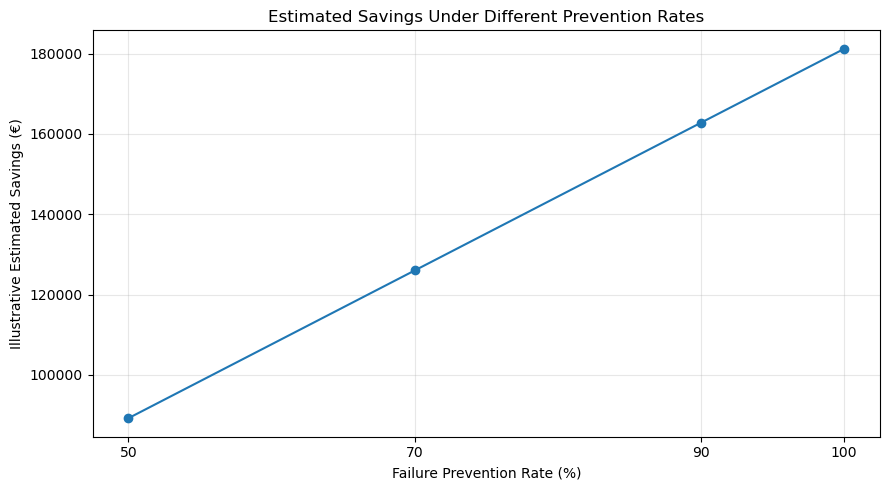

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    sensitivity_df["Prevention rate"] * 100,
    sensitivity_df["Estimated savings (€)"],
    marker="o"
)

plt.title("Estimated Savings Under Different Prevention Rates")
plt.xlabel("Failure Prevention Rate (%)")
plt.ylabel("Illustrative Estimated Savings (€)")
plt.xticks([50, 70, 90, 100])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Sensitivity Analysis: Failure Prevention Rate

The estimated business impact was evaluated under prevention rates of
50%, 70%, 90%, and 100%.

Under the illustrative cost assumptions, estimated savings ranged from
€89,200 at a 50% prevention rate to €181,200 at a 100% prevention rate.

The analysis demonstrates that potential business value depends not only
on predictive performance but also on the effectiveness of maintenance
actions taken after an alert.

These figures are illustrative and are not actual Arla savings or
validated industrial cost estimates. The calculation excludes model
implementation and ongoing operating costs, and assumes planned
maintenance costs are incurred only for successfully prevented failures.

In [43]:
import pandas as pd

# Illustrative assumptions — not actual Arla costs
cost_unexpected_failure = 5000
cost_planned_maintenance = 1000
cost_false_alarm = 200

# Test-set results at threshold 0.30
true_positives = 46
false_negatives = 22
false_positives = 14

# Baseline: all 68 failures occur unexpectedly
baseline_cost = (
    (true_positives + false_negatives)
    * cost_unexpected_failure
)

# Test different proportions of detected failures prevented
prevention_rates = [0.50, 0.70, 0.90, 1.00]

refined_results = []

for prevention_rate in prevention_rates:

    # Every detected failure receives planned maintenance
    planned_maintenance_cost = (
        true_positives * cost_planned_maintenance
    )

    # Some detected failures are not successfully prevented
    unprevented_detected_failures = (
        true_positives * (1 - prevention_rate)
    )

    # These plus false negatives still incur unexpected-failure costs
    unexpected_failure_cost = (
        unprevented_detected_failures + false_negatives
    ) * cost_unexpected_failure

    # False alarms require investigation
    false_alarm_cost = (
        false_positives * cost_false_alarm
    )

    scenario_cost = (
        planned_maintenance_cost
        + unexpected_failure_cost
        + false_alarm_cost
    )

    savings = baseline_cost - scenario_cost

    refined_results.append({
        "Prevention rate": prevention_rate,
        "Planned maintenance cost (€)": planned_maintenance_cost,
        "Unexpected failure cost (€)": unexpected_failure_cost,
        "False alarm cost (€)": false_alarm_cost,
        "Scenario cost (€)": scenario_cost,
        "Estimated savings (€)": savings,
        "Cost reduction (%)": savings / baseline_cost * 100
    })

refined_sensitivity_df = pd.DataFrame(refined_results)

display(refined_sensitivity_df.round(2))

,Prevention rate,Planned maintenance cost (€),Unexpected failure cost (€),False alarm cost (€),Scenario cost (€),Estimated savings (€),Cost reduction (%)
0,0.5,46000,225000.0,2800,273800.0,66200.0,19.47
1,0.7,46000,179000.0,2800,227800.0,112200.0,33.00
2,0.9,46000,133000.0,2800,181800.0,158200.0,46.53
3,1.0,46000,110000.0,2800,158800.0,181200.0,53.29


### Refined Business-Impact Scenario Analysis

The business-impact model was refined to account for planned maintenance
costs for every failure detected by the model, regardless of whether
the intervention successfully prevents the failure.

Under the illustrative assumptions, estimated savings range from
€66,200 at a 50% prevention rate to €181,200 at a 100% prevention rate.

At a 70% prevention rate, the scenario estimates:
- Planned maintenance cost: €46,000
- Unexpected failure cost: €179,000
- False-alarm investigation cost: €2,800
- Total scenario cost: €227,800
- Estimated savings relative to the baseline: €112,200
- Illustrative cost reduction: 33.0%

These are scenario estimates, not actual Arla savings. The analysis uses
synthetic machine data and illustrative costs, and excludes implementation,
monitoring, and ongoing model-operating costs.

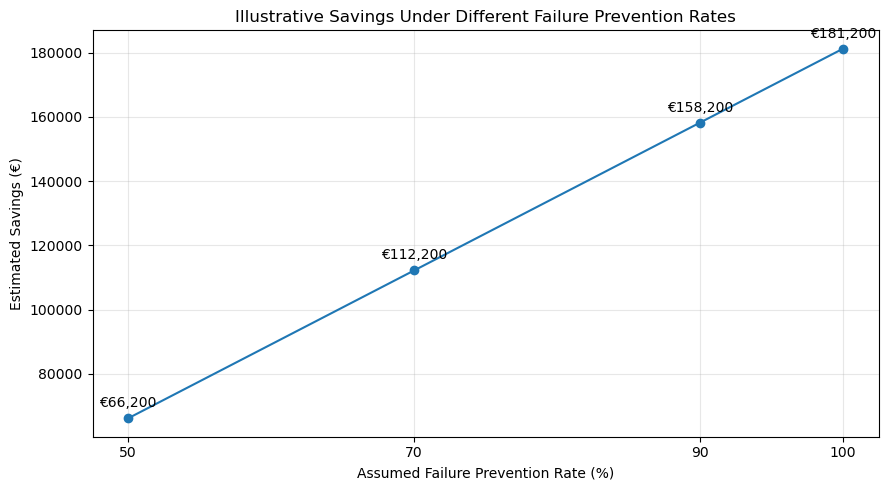

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    refined_sensitivity_df["Prevention rate"] * 100,
    refined_sensitivity_df["Estimated savings (€)"],
    marker="o"
)

for x, y in zip(
    refined_sensitivity_df["Prevention rate"] * 100,
    refined_sensitivity_df["Estimated savings (€)"]
):
    plt.annotate(
        f"€{y:,.0f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.title("Illustrative Savings Under Different Failure Prevention Rates")
plt.xlabel("Assumed Failure Prevention Rate (%)")
plt.ylabel("Estimated Savings (€)")
plt.xticks([50, 70, 90, 100])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

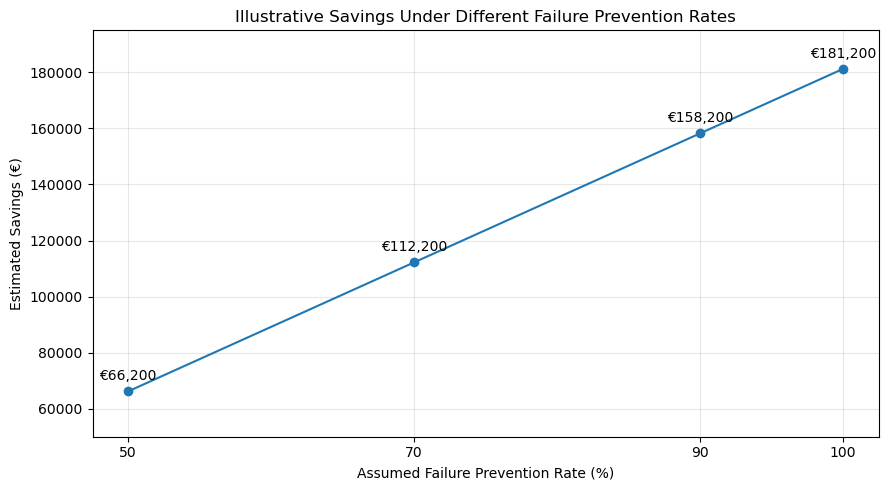

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

x = refined_sensitivity_df["Prevention rate"] * 100
y = refined_sensitivity_df["Estimated savings (€)"]

plt.plot(x, y, marker="o")

for x_value, y_value in zip(x, y):
    plt.annotate(
        f"€{y_value:,.0f}",
        (x_value, y_value),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.title("Illustrative Savings Under Different Failure Prevention Rates")
plt.xlabel("Assumed Failure Prevention Rate (%)")
plt.ylabel("Estimated Savings (€)")
plt.xticks([50, 70, 90, 100])
plt.ylim(50000, 195000)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [46]:
# Define the target: whether the machine experienced a failure
target = "Machine failure"

# Columns to exclude from model training
exclude_columns = [
    "UDI",                 # Unique row identifier
    "Product ID",          # Product label
    "Machine failure",     # Target variable
    "TWF", "HDF", "PWF", "OSF", "RNF"  # Failure-type flags; avoid target leakage
]

# Create features (X) and target (y)
X = df.drop(columns=exclude_columns)
y = df[target]

print("Feature columns:")
print(X.columns.tolist())

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

Feature columns:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Any failure mode']

Features shape: (10000, 7)
Target shape: (10000,)


In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nFailure counts in training set:")
print(y_train.value_counts())

print("\nFailure counts in testing set:")
print(y_test.value_counts())

Training features: (8000, 7)
Testing features: (2000, 7)

Failure counts in training set:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Failure counts in testing set:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Identify numeric and categorical features
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

categorical_features = ["Type"]

# Apply suitable preprocessing to each feature type
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [49]:
from sklearn.linear_model import LogisticRegression

# Combine preprocessing and Logistic Regression into one pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [50]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

# Predict failure classes and failure probabilities
y_pred_logistic = logistic_model.predict(X_test)
y_proba_logistic = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

print("\nClassification report:")
print(classification_report(y_test, y_pred_logistic, zero_division=0))

print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_logistic), 3))
print("PR-AUC:", round(average_precision_score(y_test, y_proba_logistic), 3))

Confusion matrix:
[[1593  339]
 [  12   56]]

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000

ROC-AUC: 0.907
PR-AUC: 0.382


In [51]:
from sklearn.tree import DecisionTreeClassifier

# Combine preprocessing and Decision Tree
tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42
        ))
    ]
)

# Train the model
tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [52]:
# Predict failure classes and probabilities
y_pred_tree = tree_model.predict(X_test)
y_proba_tree = tree_model.predict_proba(X_test)[:, 1]

# Evaluate
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_tree))

print("\nClassification report:")
print(classification_report(y_test, y_pred_tree, zero_division=0))

print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_tree), 3))
print("PR-AUC:", round(average_precision_score(y_test, y_proba_tree), 3))

Confusion matrix:
[[1914   18]
 [  27   41]]

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.69      0.60      0.65        68

    accuracy                           0.98      2000
   macro avg       0.84      0.80      0.82      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC: 0.797
PR-AUC: 0.432


In [53]:
from sklearn.ensemble import RandomForestClassifier

# Combine preprocessing and Random Forest
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [54]:
# Predict failure classes and probabilities
y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

# Evaluate
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_rf), 3))
print("PR-AUC:", round(average_precision_score(y_test, y_proba_rf), 3))

Confusion matrix:
[[1929    3]
 [  39   29]]

Classification report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.91      0.43      0.58        68

    accuracy                           0.98      2000
   macro avg       0.94      0.71      0.78      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC: 0.964
PR-AUC: 0.772


In [55]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Split the training data into a smaller training set and validation set
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train a temporary Random Forest on the smaller training set
rf_validation_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_validation_model.fit(X_train_sub, y_train_sub)

# Get predicted failure probabilities for the validation set
y_proba_val = rf_validation_model.predict_proba(X_val)[:, 1]

# Compare different probability thresholds
thresholds = [0.50, 0.40, 0.30, 0.20, 0.10, 0.05]

for threshold in thresholds:
    y_pred_threshold = (y_proba_val >= threshold).astype(int)

    precision = precision_score(
        y_val, y_pred_threshold, zero_division=0
    )
    recall = recall_score(
        y_val, y_pred_threshold, zero_division=0
    )
    f1 = f1_score(
        y_val, y_pred_threshold, zero_division=0
    )

    alerts = y_pred_threshold.sum()

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f} | "
        f"Alerts: {alerts}"
    )

Threshold: 0.50 | Precision: 0.885 | Recall: 0.426 | F1: 0.575 | Alerts: 26
Threshold: 0.40 | Precision: 0.853 | Recall: 0.537 | F1: 0.659 | Alerts: 34
Threshold: 0.30 | Precision: 0.686 | Recall: 0.648 | F1: 0.667 | Alerts: 51
Threshold: 0.20 | Precision: 0.533 | Recall: 0.741 | F1: 0.620 | Alerts: 75
Threshold: 0.10 | Precision: 0.373 | Recall: 0.815 | F1: 0.512 | Alerts: 118
Threshold: 0.05 | Precision: 0.265 | Recall: 0.926 | F1: 0.412 | Alerts: 189


In [56]:
from sklearn.metrics import confusion_matrix, classification_report

# Get failure probabilities from the trained Random Forest
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

# Apply our selected threshold
chosen_threshold = 0.30
y_pred_rf_030 = (y_proba_rf >= chosen_threshold).astype(int)

# Evaluate
print("Confusion matrix at threshold 0.30:")
print(confusion_matrix(y_test, y_pred_rf_030))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_rf_030,
    zero_division=0
))

print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_rf), 3))
print("PR-AUC:", round(average_precision_score(y_test, y_proba_rf), 3))

Confusion matrix at threshold 0.30:
[[1917   15]
 [  22   46]]

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.75      0.68      0.71        68

    accuracy                           0.98      2000
   macro avg       0.87      0.83      0.85      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC: 0.965
PR-AUC: 0.775


In [57]:
import joblib
from pathlib import Path

model_dir = project_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "random_forest_pipeline.joblib"

joblib.dump(rf_model, model_path)

# Save the selected decision threshold separately
threshold_path = model_dir / "decision_threshold.txt"
threshold_path.write_text("0.30")

print("Model saved to:", model_path)
print("Decision threshold saved to:", threshold_path)

Model saved to: C:\Users\hp\Documents\GitHub\predictive-maintenance-dairy\models\random_forest_pipeline.joblib
Decision threshold saved to: C:\Users\hp\Documents\GitHub\predictive-maintenance-dairy\models\decision_threshold.txt


In [58]:
# Illustrative business assumptions — not actual Arla cost data

cost_unexpected_failure = 5000  # € per unexpected failure
cost_planned_maintenance = 1000  # € per planned maintenance intervention
cost_false_alarm = 200  # € per unnecessary alert investigation

baseline_cost = 68 * cost_unexpected_failure

print(f"Baseline cost (no predictive maintenance): €{baseline_cost:,.0f}")

Baseline cost (no predictive maintenance): €340,000


In [59]:
# Model results at threshold 0.30
TP = 46  # detected failures
FN = 22  # missed failures
FP = 15  # false alarms

prevention_rate = 0.70  # illustrative assumption

planned_maintenance_cost = TP * cost_planned_maintenance

failures_not_prevented = TP * (1 - prevention_rate)
unexpected_failure_cost = (failures_not_prevented + FN) * cost_unexpected_failure

false_alarm_cost = FP * cost_false_alarm

scenario_cost = (
    planned_maintenance_cost
    + unexpected_failure_cost
    + false_alarm_cost
)

estimated_savings = baseline_cost - scenario_cost
savings_percentage = estimated_savings / baseline_cost * 100

print(f"Planned maintenance cost: €{planned_maintenance_cost:,.0f}")
print(f"Unexpected failure cost: €{unexpected_failure_cost:,.0f}")
print(f"False alarm investigation cost: €{false_alarm_cost:,.0f}")
print("-" * 40)
print(f"Estimated scenario cost: €{scenario_cost:,.0f}")
print(f"Estimated savings: €{estimated_savings:,.0f}")
print(f"Estimated cost reduction: {savings_percentage:.2f}%")

Planned maintenance cost: €46,000
Unexpected failure cost: €179,000
False alarm investigation cost: €3,000
----------------------------------------
Estimated scenario cost: €228,000
Estimated savings: €112,000
Estimated cost reduction: 32.94%


In [60]:
import pandas as pd

prevention_rates = [0.50, 0.70, 0.90, 1.00]

scenario_results = []

for rate in prevention_rates:
    planned_cost = TP * cost_planned_maintenance

    failures_not_prevented = TP * (1 - rate)
    unexpected_cost = (failures_not_prevented + FN) * cost_unexpected_failure

    false_alarm_cost = FP * cost_false_alarm

    total_cost = planned_cost + unexpected_cost + false_alarm_cost
    savings = baseline_cost - total_cost
    savings_pct = savings / baseline_cost * 100

    scenario_results.append({
        "Prevention Rate": f"{rate:.0%}",
        "Planned Maintenance (€)": planned_cost,
        "Unexpected Failures (€)": unexpected_cost,
        "False Alarm Investigations (€)": false_alarm_cost,
        "Total Scenario Cost (€)": total_cost,
        "Estimated Savings (€)": savings,
        "Cost Reduction (%)": savings_pct
    })

impact_df = pd.DataFrame(scenario_results)

impact_df

,Prevention Rate,Planned Maintenance (€),Unexpected Failures (€),False Alarm Investigations (€),Total Scenario Cost (€),Estimated Savings (€),Cost Reduction (%)
0,50%,46000,225000.0,3000,274000.0,66000.0,19.411765
1,70%,46000,179000.0,3000,228000.0,112000.0,32.941176
2,90%,46000,133000.0,3000,182000.0,158000.0,46.470588
3,100%,46000,110000.0,3000,159000.0,181000.0,53.235294


In [61]:
impact_df = impact_df.set_index("Prevention Rate")
impact_df

,Planned Maintenance (€),Unexpected Failures (€),False Alarm Investigations (€),Total Scenario Cost (€),Estimated Savings (€),Cost Reduction (%)
Prevention Rate,,,,,,
50%,46000,225000.0,3000,274000.0,66000.0,19.411765
70%,46000,179000.0,3000,228000.0,112000.0,32.941176
90%,46000,133000.0,3000,182000.0,158000.0,46.470588
100%,46000,110000.0,3000,159000.0,181000.0,53.235294


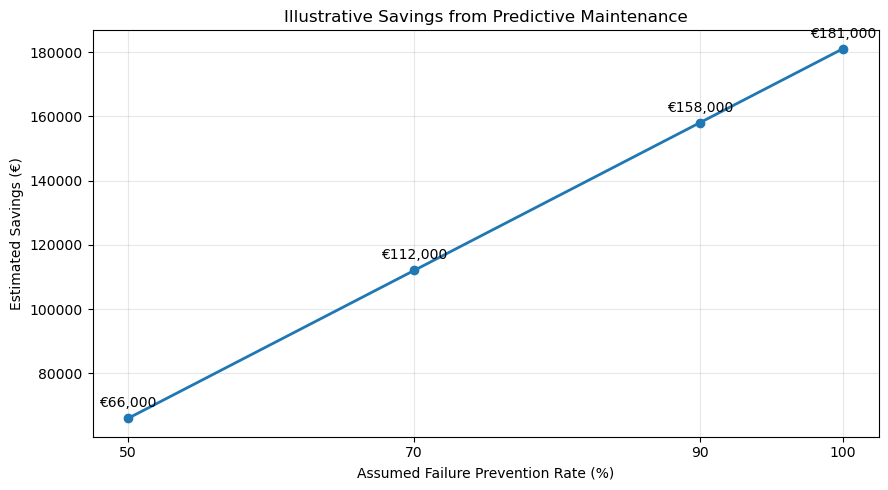

In [62]:
import matplotlib.pyplot as plt

# Extract values from the business-impact table
prevention_rates = [50, 70, 90, 100]
estimated_savings = impact_df["Estimated Savings (€)"].values

plt.figure(figsize=(9, 5))

plt.plot(
    prevention_rates,
    estimated_savings,
    marker="o",
    linewidth=2
)

plt.title("Illustrative Savings from Predictive Maintenance")
plt.xlabel("Assumed Failure Prevention Rate (%)")
plt.ylabel("Estimated Savings (€)")

plt.xticks(prevention_rates)
plt.grid(True, alpha=0.3)

# Add value labels
for x, y in zip(prevention_rates, estimated_savings):
    plt.annotate(
        f"€{y:,.0f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.tight_layout()
plt.show()

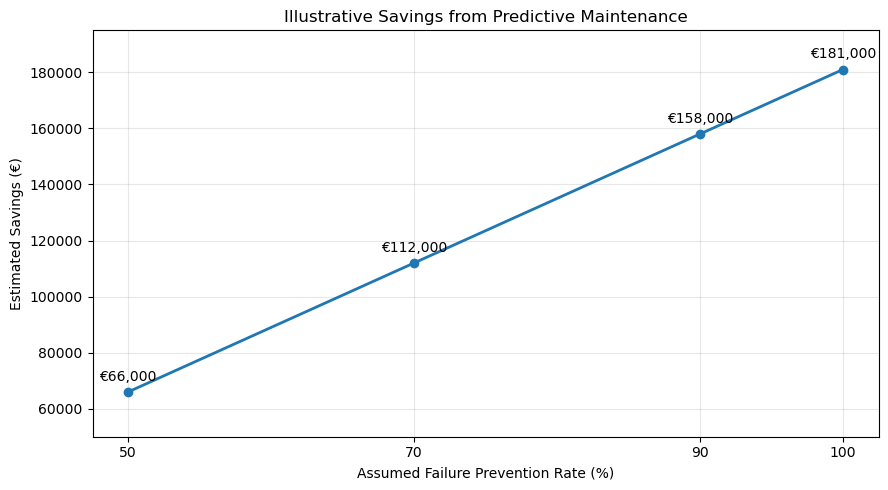

In [67]:
plt.figure(figsize=(9, 5))

plt.plot(
    prevention_rates,
    estimated_savings,
    marker="o",
    linewidth=2
)

plt.title("Illustrative Savings from Predictive Maintenance")
plt.xlabel("Assumed Failure Prevention Rate (%)")
plt.ylabel("Estimated Savings (€)")

plt.xticks(prevention_rates)
plt.ylim(50000, 195000)
plt.grid(True, alpha=0.3)

for x, y in zip(prevention_rates, estimated_savings):
    plt.annotate(
        f"€{y:,.0f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.tight_layout()
plt.show()

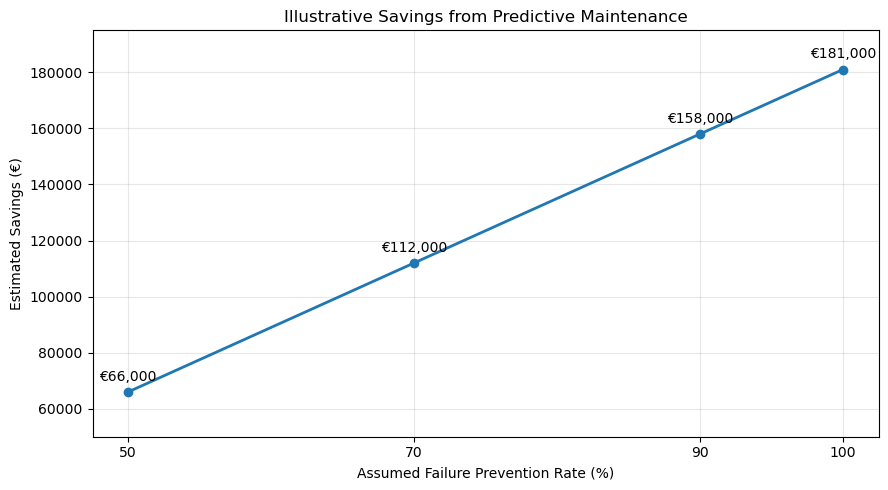

Chart saved to: C:\Users\hp\Documents\GitHub\predictive-maintenance-dairy\reports\figures\illustrative_savings_chart.png


In [68]:
import matplotlib.pyplot as plt

figures_dir = project_dir / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

figure_path = figures_dir / "illustrative_savings_chart.png"

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(prevention_rates, estimated_savings, marker="o", linewidth=2)

ax.set_title("Illustrative Savings from Predictive Maintenance")
ax.set_xlabel("Assumed Failure Prevention Rate (%)")
ax.set_ylabel("Estimated Savings (€)")
ax.set_xticks(prevention_rates)
ax.set_ylim(50000, 195000)
ax.grid(True, alpha=0.3)

for x, y in zip(prevention_rates, estimated_savings):
    ax.annotate(
        f"€{y:,.0f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

fig.tight_layout()

# Save the actual figure object
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Chart saved to:", figure_path)

### Model Interpretability – Feature Importance

In [70]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nDoes the model exist at the current location?")
print(Path("models/random_forest_pipeline.joblib").exists())

print("\nDoes the model exist in the GitHub project folder?")
project_dir = Path(
    r"C:\Users\hp\Documents\GitHub\predictive-maintenance-dairy"
)

model_path = project_dir / "models" / "random_forest_pipeline.joblib"

print(model_path)
print(model_path.exists())

Current working directory:
C:\Users\hp\Documents\GitHub\predictive-maintenance-dairy\notebooks

Does the model exist at the current location?
False

Does the model exist in the GitHub project folder?
C:\Users\hp\Documents\GitHub\predictive-maintenance-dairy\models\random_forest_pipeline.joblib
True


In [71]:
import joblib

model = joblib.load(model_path)

print("Random Forest pipeline loaded successfully!")

Random Forest pipeline loaded successfully!


,Feature,Importance
2,num__Rotational speed [rpm],0.309927
3,num__Torque [Nm],0.292754
4,num__Tool wear [min],0.200449
0,num__Air temperature [K],0.103700
1,num__Process temperature [K],0.073200
6,cat__Type_L,0.009904
7,cat__Type_M,0.006288
5,cat__Type_H,0.003777


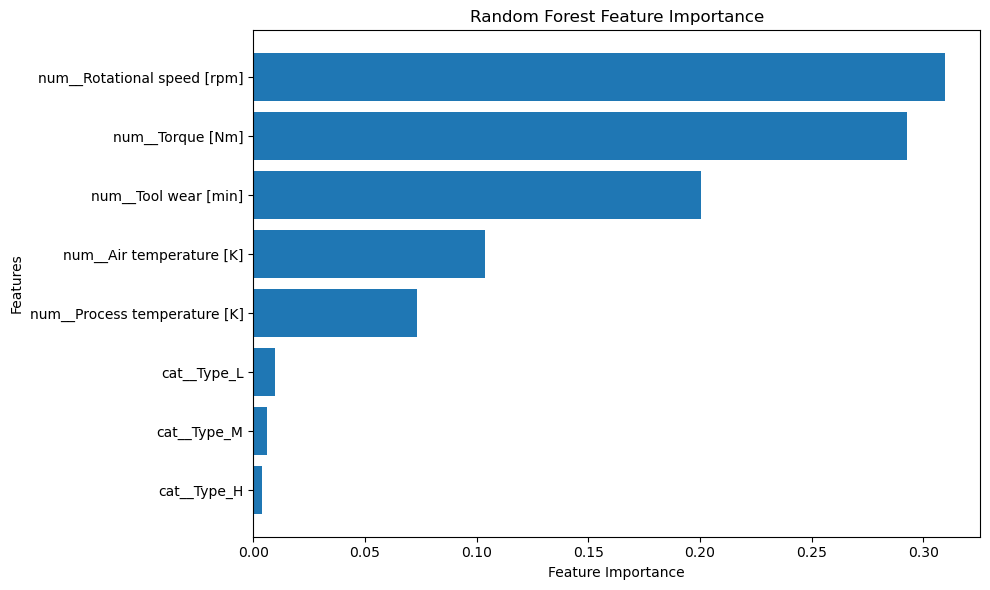

In [73]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract preprocessing and Random Forest components
preprocessor = model[:-1]
classifier = model.steps[-1][1]

# Obtain transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Extract feature importance
importance = classifier.feature_importances_

# Create and sort the feature importance dataframe
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

# Display results
display(importance_df)

# Visualise the top 15 features
plt.figure(figsize=(10, 6))

top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [74]:
try:
    import shap
    print("SHAP is installed.")
    print("Version:", shap.__version__)
except ImportError:
    print("SHAP is not installed.")

SHAP is not installed.


In [76]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   --------------------------- ------------ 524.3/751.9 kB 1.3 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 1.2 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


In [77]:
import shap

print("SHAP installed successfully!")
print("Version:", shap.__version__)

SHAP installed successfully!
Version: 0.54.1


In [78]:
# Select a sample of the test data for SHAP analysis
X_shap = X_test.sample(n=300, random_state=42)

# Transform the data using the trained model's preprocessing pipeline
preprocessor = model[:-1]
classifier = model.steps[-1][1]

X_shap_transformed = preprocessor.transform(X_shap)

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Convert to a DataFrame for easier interpretation
X_shap_transformed = pd.DataFrame(
    X_shap_transformed,
    columns=feature_names,
    index=X_shap.index
)

print("SHAP sample shape:", X_shap_transformed.shape)
display(X_shap_transformed.head())

SHAP sample shape: (300, 8)


,num__Air temperature [K],num__Process temperature [K],num__Rotational speed [rpm],num__Torque [Nm],num__Tool wear [min],cat__Type_H,cat__Type_L,cat__Type_M
4701,1.749397,1.147115,0.250741,-0.729022,0.560974,1.0,0.0,0.0
8311,-0.604270,-0.003278,-1.362479,1.270032,-0.521206,0.0,0.0,1.0
204,-0.804582,-1.018330,1.127127,-0.719027,0.074777,0.0,1.0,0.0
4985,1.899631,2.026827,1.395066,-1.648588,1.690206,0.0,0.0,1.0
6816,0.447369,0.470413,-0.346541,0.320481,0.560974,0.0,1.0,0.0


In [79]:
# Create a SHAP TreeExplainer for the trained Random Forest
explainer = shap.TreeExplainer(classifier)

# Calculate SHAP values
shap_explanation = explainer(X_shap_transformed)

# Display the resulting dimensions
print("SHAP values shape:", shap_explanation.values.shape)
print("Base values shape:", shap_explanation.base_values.shape)

print("\nSHAP values calculated successfully!")

SHAP values shape: (300, 8, 2)
Base values shape: (300, 2)

SHAP values calculated successfully!


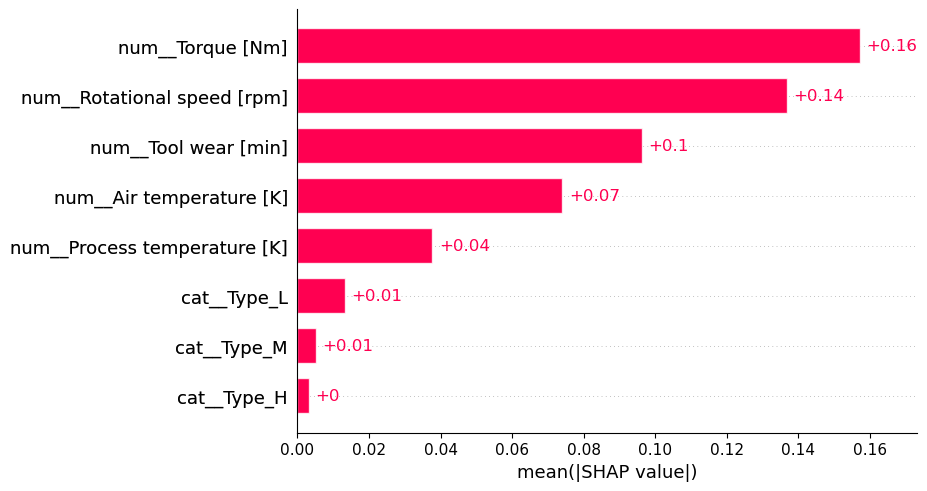

In [80]:
# Extract SHAP values for Class 1 (machine failure)
shap_values_failure = shap.Explanation(
    values=shap_explanation.values[:, :, 1],
    base_values=shap_explanation.base_values[:, 1],
    data=X_shap_transformed.values,
    feature_names=X_shap_transformed.columns
)

# Create SHAP summary bar plot
shap.plots.bar(shap_values_failure, max_display=8)

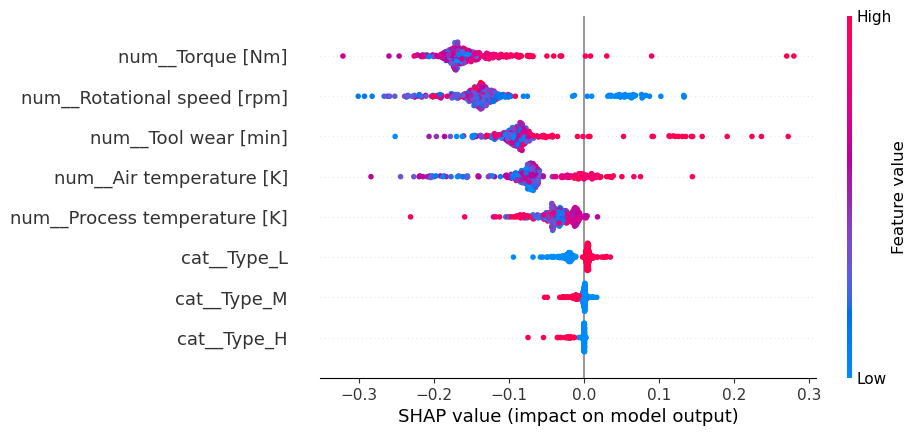

In [81]:
# SHAP beeswarm plot for machine failure (Class 1)
shap.plots.beeswarm(
    shap_values_failure,
    max_display=8
)

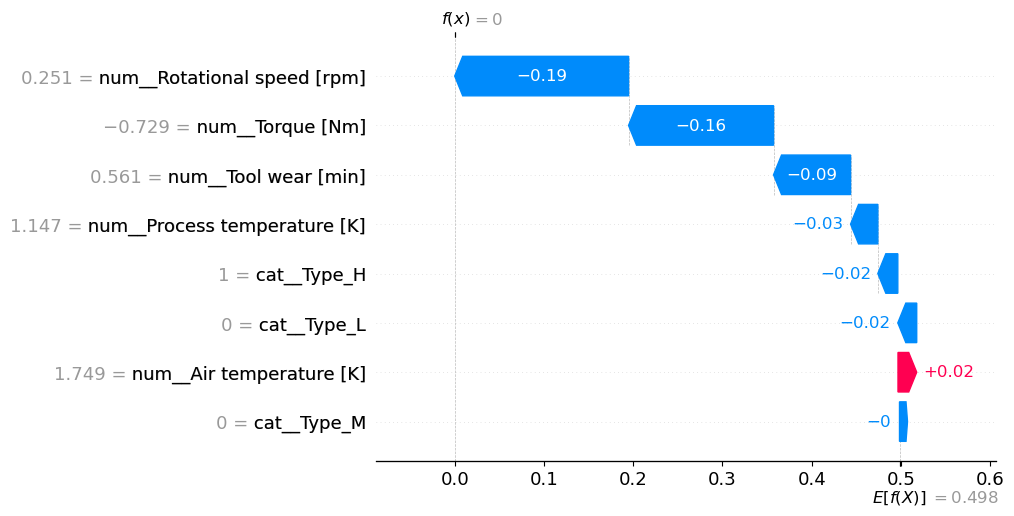

In [82]:
# Select the first machine in our SHAP sample
machine_index = 0

# Display its SHAP waterfall plot
shap.plots.waterfall(
    shap_values_failure[machine_index],
    max_display=8
)

In [83]:
# Retrieve the original machine record
machine = X_shap.iloc[[machine_index]]

# Get the actual failure probability
failure_probability = model.predict_proba(machine)[0, 1]

# Apply our selected decision threshold
prediction = int(failure_probability >= threshold)

print("Machine ID:", machine.index[0])
print(f"Failure probability: {failure_probability:.4%}")
print("Decision threshold:", threshold)
print("Predicted failure:", "Yes" if prediction == 1 else "No")

print("\nOriginal sensor measurements:")
display(machine)

Machine ID: 4701
Failure probability: 0.0000%
Decision threshold: 0.05
Predicted failure: No

Original sensor measurements:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Any failure mode
4701,H,303.5,311.7,1584,32.7,143,0


In [84]:
from pathlib import Path

project_dir = Path.cwd().parent

threshold_file = project_dir / "models" / "decision_threshold.txt"

saved_threshold = float(threshold_file.read_text().strip())

print("Current notebook threshold:", threshold)
print("Saved project threshold:", saved_threshold)

print("\nActual dataset label:")
print("Machine failure:", y_test.loc[4701])

Current notebook threshold: 0.05
Saved project threshold: 0.3

Actual dataset label:
Machine failure: 0


In [85]:
# Use the official project decision threshold
threshold = saved_threshold

print("Updated decision threshold:", threshold)

Updated decision threshold: 0.3


In [86]:
failure_probability = model.predict_proba(X_shap.iloc[[machine_index]])[0, 1]

prediction = int(failure_probability >= threshold)

print(f"Failure probability: {failure_probability:.6%}")
print(f"Decision threshold: {threshold:.2f}")
print("Predicted failure:", "Yes" if prediction == 1 else "No")
print("Actual failure:", int(y_test.loc[4701]))

Failure probability: 0.000000%
Decision threshold: 0.30
Predicted failure: No
Actual failure: 0


In [87]:
from pathlib import Path
import matplotlib.pyplot as plt

# Create the figures directory
figures_dir = project_dir / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# 1. SHAP feature importance
shap.plots.bar(shap_values_failure, max_display=8, show=False)
plt.gcf().savefig(
    figures_dir / "shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# 2. SHAP beeswarm plot
shap.plots.beeswarm(shap_values_failure, max_display=8, show=False)
plt.gcf().savefig(
    figures_dir / "shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# 3. SHAP waterfall plot
shap.plots.waterfall(shap_values_failure[machine_index], max_display=8, show=False)
plt.gcf().savefig(
    figures_dir / "shap_waterfall_machine_4701.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

print("All three SHAP figures saved successfully!")

for file in figures_dir.glob("shap_*.png"):
    print(file.name)

All three SHAP figures saved successfully!
shap_beeswarm.png
shap_feature_importance.png
shap_waterfall_machine_4701.png
